In [2]:
import pandas as pd


In [3]:
df=pd.read_csv (r"C:\Users\hp1\Documents\estarta\df_file.csv")

In [4]:
df.head(10)



,Text,Label
0,Budget to set scene for election\n \n Gordon B...,0
1,Army chiefs in regiments decision\n \n Militar...,0
2,Howard denies split over ID cards\n \n Michael...,0
3,Observers to monitor UK election\n \n Minister...,0
4,Kilroy names election seat target\n \n Ex-chat...,0
5,Donor attacks Blair-Brown 'feud'\n \n The repo...,0
6,Research fears over Kelly's views\n \n Scienti...,0
7,Chancellor rallies Labour voters\n \n Gordon B...,0
8,Fox attacks Blair's Tory 'lies'\n \n Tony Blai...,0
9,Tories unveil quango blitz plans\n \n Plans to...,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Text    2225 non-null   object
 1   Label   2225 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 34.9+ KB


In [6]:
df.shape

(2225, 2)

In [7]:
df.columns

Index(['Text', 'Label'], dtype='object')

In [8]:
df.describe()

,Label
count,2225.000000
mean,2.027416
std,1.438694
min,0.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,4.000000


In [9]:
df.isnull().sum()

Text     0
Label    0
dtype: int64

In [10]:
# Count empty strings in the "Text" column
df["Text"].str.strip().eq("").sum()


np.int64(0)

EDA Observation — Missing Values

The dataset contains 2,225 rows and 2 columns. No missing values were found in either the Text or Label column. Additionally, no empty or whitespace-only text entries were detected. Therefore, no missing-value handling is required at this stage.

In [11]:
df.duplicated().sum()

np.int64(98)

In [12]:
#to find the duplicated rows in the dataframe
df[df.duplicated()] 

,Text,Label
59,Blair backs 'pre-election budget'\n \n Tony Bl...,0
155,'Debate needed' on donations cap\n \n A cap on...,0
186,Howard denies split over ID cards\n \n Michael...,0
216,Kennedy questions trust of Blair\n \n Lib Dem ...,0
226,Fox attacks Blair's Tory 'lies'\n \n Tony Blai...,0
...,...,...
1954,S Korea spending boost to economy\n \n South K...,4
1992,Jobs growth still slow in the US\n \n The US c...,4
2105,Steady job growth continues in US\n \n The US ...,4
2186,SEC to rethink post-Enron rules\n \n The US st...,4


In [13]:

#  Create a DataFrame without duplicates
df_clean = df.drop_duplicates().copy()

In [14]:
df_clean.shape


(2127, 2)

In [15]:
# label distribution
# count the number of occurrences of each label in the "Label" column
label_counts = df_clean["Label"].value_counts().sort_index()

label_counts

Label
0    403
1    505
2    347
3    369
4    503
Name: count, dtype: int64

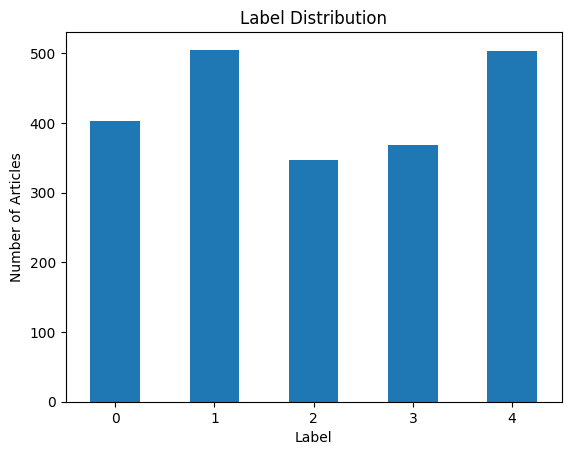

In [16]:
import matplotlib.pyplot as plt

label_counts.plot(kind="bar")

plt.title("Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)

plt.show()

Label Distribution Observation

The dataset contains five categories (0–4). After removing duplicates, Label 1 has the highest number of articles (505), while Label 2 has the lowest (347). The dataset shows some differences in class sizes.

In [17]:
#text length distribution 
#character count
df_clean["char_count"] = df_clean["Text"].str.len()

df_clean[["Text", "char_count"]].head()

,Text,char_count
0,Budget to set scene for election\n \n Gordon B...,3147
1,Army chiefs in regiments decision\n \n Militar...,3026
2,Howard denies split over ID cards\n \n Michael...,3167
3,Observers to monitor UK election\n \n Minister...,3094
4,Kilroy names election seat target\n \n Ex-chat...,2614


In [18]:
#word count
df_clean["word_count"] = df_clean["Text"].str.split().str.len()

df_clean[["Text", "word_count"]].head()

,Text,word_count
0,Budget to set scene for election\n \n Gordon B...,538
1,Army chiefs in regiments decision\n \n Militar...,500
2,Howard denies split over ID cards\n \n Michael...,540
3,Observers to monitor UK election\n \n Minister...,496
4,Kilroy names election seat target\n \n Ex-chat...,440


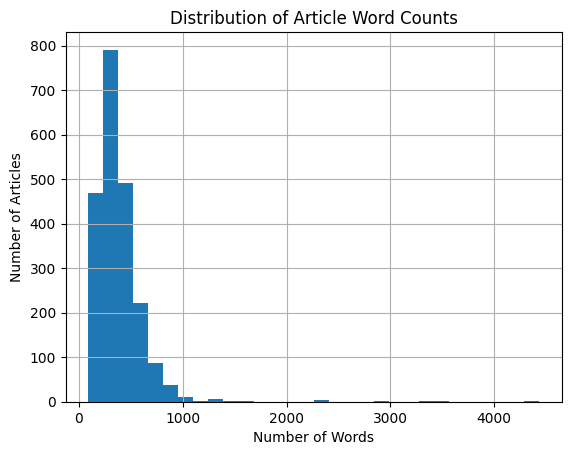

In [19]:
import matplotlib.pyplot as plt

df_clean["word_count"].hist(bins=30)

plt.title("Distribution of Article Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")

plt.show()

In [20]:
# all words
all_words = " ".join(df_clean["Text"]).lower().split()

len(all_words)

817008

In [21]:
#unique words
vocabulary = set(all_words)

len(vocabulary)

60616

Vocabulary Analysis Observation

Vocabulary analysis was performed to examine the total number of words and unique words in the dataset. All articles were converted to lowercase and split into words. A Python set was used to identify unique words. The vocabulary size may change after text cleaning and normalization.

In [22]:
#word frequency
from collections import Counter

word_counts = Counter(all_words)
# Get the 10 most common words and their counts
top_10 = word_counts.most_common(10)

top_10

[('the', 49470),
 ('to', 23738),
 ('of', 18971),
 ('and', 17563),
 ('a', 17337),
 ('in', 16657),
 ('for', 8426),
 ('is', 8092),
 ('that', 7283),
 ('on', 7091)]

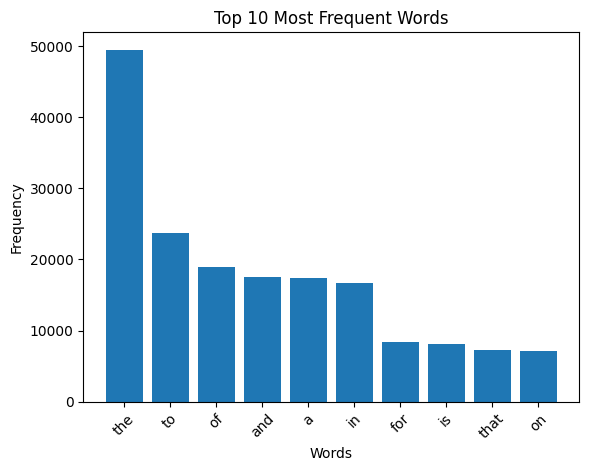

In [23]:
import matplotlib.pyplot as plt

words = [item[0] for item in top_10]
counts = [item[1] for item in top_10]

plt.bar(words, counts)

plt.title("Top 10 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.show()

In [24]:
#Language Detection
from langdetect import detect, DetectorFactory, LangDetectException

DetectorFactory.seed = 0

def detect_language(text: str) -> str:
    """Detect the primary language of a text."""
    try:
        return detect(text)
    except LangDetectException:
        return "unknown"

In [25]:
df_clean["language"] = df_clean["Text"].apply(detect_language)

df_clean[["Text", "language"]].head()

,Text,language
0,Budget to set scene for election\n \n Gordon B...,en
1,Army chiefs in regiments decision\n \n Militar...,en
2,Howard denies split over ID cards\n \n Michael...,en
3,Observers to monitor UK election\n \n Minister...,en
4,Kilroy names election seat target\n \n Ex-chat...,en


In [26]:
#noise detection
#Detect URLs
url_mask = df_clean["Text"].str.contains(
    r"https?://\S+|www\.\S+",
    regex=True
)

url_mask.sum()

np.int64(2)

In [27]:
url_mask

0       False
1       False
2       False
3       False
4       False
        ...  
2220    False
2221    False
2222    False
2223    False
2224    False
Name: Text, Length: 2127, dtype: bool

In [28]:
#Detect Numbers
digit_mask = df_clean["Text"].str.contains(
    r"\d",
    regex=True
)

digit_mask.sum()

np.int64(2023)

In [29]:
#Detect Special Characters
special_mask = df_clean["Text"].str.contains(
    r"[^a-zA-Z0-9\s]",
    regex=True
)

special_mask.sum()

np.int64(2127)

In [30]:
#Detect Encoding Issues
encoding_mask = df_clean["Text"].str.contains(
    r"Â£|â€™|â€œ|â€|Ã",
    regex=True
)

encoding_mask.sum()

np.int64(618)

Noise Detection Observation

Noise detection was performed using regular expressions. The dataset contains URLs, numerical values, special characters, repeated whitespace, and potential encoding issues. These findings will guide the text normalization process. Numbers and punctuation should not be removed automatically because they may contain useful information.

In [31]:
import re

def normalize_text(text: str) -> str:
    """Normalize text by lowercasing and removing URLs and extra spaces."""

    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text)
    text = text.strip()

    return text

In [32]:
df_clean["normalized_text"] = df_clean["Text"].apply(normalize_text)

df_clean[["Text", "normalized_text"]].head()

,Text,normalized_text
0,Budget to set scene for election\n \n Gordon B...,budget to set scene for election gordon brown ...
1,Army chiefs in regiments decision\n \n Militar...,army chiefs in regiments decision military chi...
2,Howard denies split over ID cards\n \n Michael...,howard denies split over id cards michael howa...
3,Observers to monitor UK election\n \n Minister...,observers to monitor uk election ministers wil...
4,Kilroy names election seat target\n \n Ex-chat...,kilroy names election seat target ex-chat show...


In [44]:
df_clean[
    ["Text", "Label", "normalized_text"]
].to_csv("news_preprocessed.csv", index=False)

Text Normalization Observation

Basic text normalization was applied to the dataset. The process included lowercasing, URL removal, and whitespace normalization. A reusable Python function was created using type hints and a docstring. The normalized text was stored in a new column while preserving the original text.

In [33]:
#tokenization
import spacy

nlp = spacy.load("en_core_web_sm")

In [34]:
def tokenize_text(text: str) -> list[str]:
    """Split text into tokens using spaCy."""

    doc = nlp(text)

    tokens = [token.text for token in doc]

    return tokens

In [35]:
# apply the tokenize_text 
df_clean["tokens"] = df_clean["normalized_text"].apply(tokenize_text)

df_clean[["normalized_text", "tokens"]].head()

,normalized_text,tokens
0,budget to set scene for election gordon brown ...,"[budget, to, set, scene, for, election, gordon..."
1,army chiefs in regiments decision military chi...,"[army, chiefs, in, regiments, decision, milita..."
2,howard denies split over id cards michael howa...,"[howard, denies, split, over, i, d, cards, mic..."
3,observers to monitor uk election ministers wil...,"[observers, to, monitor, uk, election, ministe..."
4,kilroy names election seat target ex-chat show...,"[kilroy, names, election, seat, target, ex, -,..."


In [36]:
# stopword removal function
def remove_stopwords(tokens: list[str]) -> list[str]:
    """Remove English stop words from a list of tokens."""

    filtered_tokens = [
        token
        for token in tokens
        if not nlp.vocab[token].is_stop
    ]

    return filtered_tokens

In [37]:
# Apply stopword removal to the dataset
df_clean["tokens_no_stopwords"] = df_clean["tokens"].apply(remove_stopwords)

df_clean[["tokens", "tokens_no_stopwords"]].head()


,tokens,tokens_no_stopwords
0,"[budget, to, set, scene, for, election, gordon...","[budget, set, scene, election, gordon, brown, ..."
1,"[army, chiefs, in, regiments, decision, milita...","[army, chiefs, regiments, decision, military, ..."
2,"[howard, denies, split, over, i, d, cards, mic...","[howard, denies, split, d, cards, michael, how..."
3,"[observers, to, monitor, uk, election, ministe...","[observers, monitor, uk, election, ministers, ..."
4,"[kilroy, names, election, seat, target, ex, -,...","[kilroy, names, election, seat, target, ex, -,..."


In [38]:
#lemmatization function
def lemmatize_text(text: str) -> list[str]:
    """Convert text tokens to their base forms using spaCy."""

    doc = nlp(text)

    lemmas = [token.lemma_ for token in doc]

    return lemmas

In [39]:
df_clean["lemmas"] = df_clean["normalized_text"].apply(lemmatize_text)

df_clean[["normalized_text", "lemmas"]].head()

,normalized_text,lemmas
0,budget to set scene for election gordon brown ...,"[budget, to, set, scene, for, election, gordon..."
1,army chiefs in regiments decision military chi...,"[army, chiefs, in, regiment, decision, militar..."
2,howard denies split over id cards michael howa...,"[howard, deny, split, over, i, d, card, michae..."
3,observers to monitor uk election ministers wil...,"[observer, to, monitor, uk, election, minister..."
4,kilroy names election seat target ex-chat show...,"[kilroy, name, election, seat, target, ex, -, ..."


In [40]:
df_clean.columns


Index(['Text', 'Label', 'char_count', 'word_count', 'language',
       'normalized_text', 'tokens', 'tokens_no_stopwords', 'lemmas'],
      dtype='object')

In [41]:
### Class Interpretation and Label Mapping

In [42]:
# Extract article titles
df_clean["title"] = df_clean["Text"].str.split("\n").str[0]

# Display sample titles from each class
for label in sorted(df_clean["Label"].unique()):
    print(f"\nClass {label}:")
    display(
        df_clean.loc[df_clean["Label"] == label, ["title"]]
        .sample(n=5, random_state=42)
    )


Class 0:


,title
71,'EU referendum could cost Â£80m'
287,MSPs hear renewed climate warning
289,Tories 'would cut number of MPs'
33,Blair backs 'pre-election budget'
42,Labour MP praises Tory campaign



Class 1:


,title
590,Rusedski angry over supplements
694,O'Sullivan commits to Dublin race
913,Vickery out of Six Nations
489,Wasps 31-37 Leicester
725,Italy 17-28 Ireland



Class 2:


,title
1298,Argonaut founder rebuilds empire
1050,Smart search lets art fans browse
1302,Parents face video game lessons
1229,Domain system scam fear
1281,Open source leaders slam patents



Class 3:


,title
1671,Wine comedy wins critics' award
1362,New York rockers top talent poll
1344,Jackson film 'absolute disaster'
1691,Ray Charles studio becomes museum
1388,Neeson in bid to revive theatre



Class 4:


,title
1986,Oil prices fall back from highs
1789,Indonesians face fuel price rise
2008,Ericsson sees earnings improve
1871,US budget deficit to reach $368bn
1820,News Corp eyes video games market
